# 01_02 Geometric and Negative Binomial

**Learning objectives**
- Model "how many trials until the first success" (Geometric) and "until the r-th success" (Negative Binomial).
- Know the two conventions (trials vs failures) and which one `scipy` uses.
- Prove memorylessness, and derive mean and variance of both distributions.
- Use the Negative Binomial for overdispersed counts where Poisson fails.

**Prerequisites:** [01_01 Bernoulli and Binomial](01_01_bernoulli_binomial.ipynb).

## 1. Setup

All imports in one cell, seeded generator for reproducibility.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- A **Bernoulli($p$) trial** succeeds with probability $p$; independent repeats give a Binomial count (lesson 01_01).
- The **PMF** lists $P(X=k)$; the **CDF** is $P(X\le k)$; the **survival function** is $P(X>k)=1-F(k)$.
- **Geometric series:** $\sum_{j=0}^{\infty} q^j=\frac1{1-q}$ for $|q|<1$, and $\sum_{j=0}^{\infty} j\,q^{j-1}=\frac1{(1-q)^2}$.
- For independent variables, means add and variances add.

## 3. Intuition and story

Keep running independent Bernoulli($p$) trials and **stop at the first success**. The number of trials needed is **Geometric($p$)**: a sales rep dials until someone buys; a download is retried until it works; a user is observed each month until they churn.

If you keep going until the **r-th success**, the number of trials is **Negative Binomial($r,p$)**. It is the sum of $r$ independent Geometric waiting times.

**Two conventions exist.** Count the *trials* including the successful one ($k=1,2,3,\dots$), or count only the *failures* before the success ($k=0,1,2,\dots$). This notebook uses the **trials convention** for the Geometric. `scipy.stats.geom` uses it too (support starts at 1). For the Negative Binomial, `scipy.stats.nbinom` counts the **failures** before the r-th success (support starts at 0), so the number of trials is `failures + r`.

## 4. Formal definition

**Geometric($p$)**, trials convention: support $k\in\{1,2,\dots\}$, parameter $p\in(0,1]$.
$$P(X=k)=(1-p)^{k-1}p,\qquad F(k)=1-(1-p)^k,\qquad P(X>k)=(1-p)^k.$$

**Negative Binomial($r,p$)**, number of trials $T$ until the $r$-th success: support $t\in\{r,r+1,\dots\}$.
$$P(T=t)=\binom{t-1}{r-1}p^r(1-p)^{t-r}.$$
In the failures convention ($Y=T-r$, what `scipy` calls `nbinom`): $P(Y=y)=\binom{y+r-1}{y}p^r(1-p)^y$, support $y\in\{0,1,\dots\}$.

## 5. Derivations

### 5.1 Geometric PMF and normalization
The first success happens on trial $k$ exactly when the first $k-1$ trials fail and trial $k$ succeeds: $(1-p)^{k-1}p$. With $q=1-p$:
$$\sum_{k=1}^{\infty}q^{k-1}p=p\cdot\frac{1}{1-q}=p\cdot\frac1p=1.$$

### 5.2 Geometric mean
$$E[X]=\sum_{k=1}^{\infty}k\,q^{k-1}p=p\cdot\frac{1}{(1-q)^2}=\frac{p}{p^2}=\frac1p.$$

### 5.3 Geometric variance
Use $E[X(X-1)]=\sum_{k=2}^{\infty}k(k-1)q^{k-1}p=pq\sum_{k=2}^{\infty}k(k-1)q^{k-2}=pq\cdot\frac{2}{(1-q)^3}=\frac{2q}{p^2}$. Then
$$\mathrm{Var}(X)=E[X(X-1)]+E[X]-E[X]^2=\frac{2q}{p^2}+\frac1p-\frac1{p^2}=\frac{2q+p-1}{p^2}=\frac{1-p}{p^2}.$$

### 5.4 Geometric PGF and MGF
$$G(s)=\sum_{k=1}^{\infty}s^kq^{k-1}p=\frac{ps}{1-qs},\qquad M(t)=\frac{pe^t}{1-qe^t}\quad (qe^t<1).$$

### 5.5 Memorylessness
For integers $m,n\ge0$, using $P(X>k)=q^k$:
$$P(X>m+n\mid X>m)=\frac{P(X>m+n)}{P(X>m)}=\frac{q^{m+n}}{q^m}=q^n=P(X>n).$$
Having already failed $m$ times tells you nothing: the process restarts fresh. The Geometric is the *only* discrete distribution on $\{1,2,\dots\}$ with this property.

### 5.6 Negative Binomial as a sum of Geometrics
The wait for the r-th success is the wait for the 1st, plus the extra wait for the 2nd, and so on. These $r$ waits are independent Geometric($p$). Hence
$$E[T]=\frac{r}{p},\qquad \mathrm{Var}(T)=\frac{r(1-p)}{p^2},\qquad G_T(s)=\Big(\frac{ps}{1-qs}\Big)^r.$$
The PMF follows by counting: the last trial is a success, and among the first $t-1$ trials exactly $r-1$ are successes, giving $\binom{t-1}{r-1}p^{r-1}q^{t-r}\cdot p$.

### 5.7 Mode, skewness, kurtosis (stated)
Geometric mode is 1; skewness $\frac{2-p}{\sqrt{1-p}}$; excess kurtosis $6+\frac{p^2}{1-p}$. Negative Binomial skewness is $\frac{2-p}{\sqrt{r(1-p)}}$ and excess kurtosis $\frac{6}{r}+\frac{p^2}{r(1-p)}$ (standard results).

### In plain words: the derivations in everyday language


- **The Geometric counts the waiting time for the first success** in independent trials with chance $p$: you fail $k-1$ times (each with probability $1-p$) and then succeed once, so $P(X=k)=(1-p)^{k-1}p$.
- **The probabilities form a geometric series,** which is why they add to 1 and why the tail has the neat form $P(X>k)=(1-p)^k$: the only way to wait more than $k$ trials is to fail $k$ times in a row.
- **Mean $1/p$:** if success has chance $1/6$ per roll you should expect to wait 6 rolls. The variance $(1-p)/p^2$ is large when $p$ is small: waiting times are very spread out.
- **Memorylessness:** having already failed 5 times tells you nothing about the future, $P(X>m+n\mid X>m)=P(X>n)$. There is no such thing as being "due" for a success.
- **The Negative Binomial is a sum of Geometrics:** the number of trials until the $r$-th success is $r$ independent Geometric waiting times, so its mean and variance are $r$ times those of one Geometric. Both are used for "how long until we have enough?" questions.
- **Careful with conventions:** this book counts the trial on which the success happens ($1,2,3,\dots$); `scipy.stats.nbinom` counts the *failures* before the $r$-th success.

## 6. Properties and relationships

- **Memorylessness** (Geometric only): the remaining wait does not depend on the past.
- **Additivity:** a sum of $r$ independent Geometric($p$) is Negative Binomial($r,p$). Independent NB($r_1,p$) + NB($r_2,p$) = NB($r_1+r_2,p$).
- **Binomial link:** "the r-th success occurs by trial $t$" is the same event as "at least $r$ successes in $t$ trials", so $P(T\le t)=P(\text{Bin}(t,p)\ge r)$.
- **Overdispersed Poisson:** if a rate $\lambda$ is itself random with a Gamma distribution and counts are Poisson($\lambda$), the counts are Negative Binomial. Mean $\mu$, variance $\mu+\mu^2/r>\mu$. Intuition only here; the full treatment is in Module 07.
- **Continuous analogue:** the Geometric is the discrete version of the Exponential (Module 02).

## 7. 2D visuals

### 7.1 Geometric PMF and CDF
With p = 0.3, the PMF drops by the constant factor 0.7 each step.

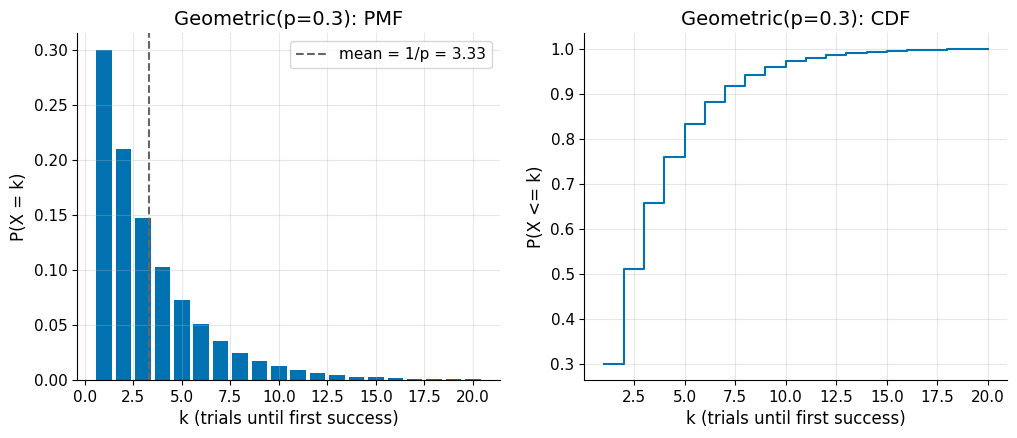

In [2]:
p = 0.3
dist = stats.geom(p=p)                     # trials convention, support 1, 2, 3, ...
k_values = np.arange(1, 21)

fig, (ax_pmf, ax_cdf) = plt.subplots(1, 2, figsize=(12, 4.5))
ax_pmf.bar(k_values, dist.pmf(k_values), color=MAIN)
ax_pmf.axvline(1 / p, color=NEUTRAL, linestyle="--", label="mean = 1/p = 3.33")
ax_pmf.set_title("Geometric(p=0.3): PMF")
ax_pmf.set_xlabel("k (trials until first success)")
ax_pmf.set_ylabel("P(X = k)")
ax_pmf.legend()

ax_cdf.step(k_values, dist.cdf(k_values), where="post", color=MAIN)
ax_cdf.set_title("Geometric(p=0.3): CDF")
ax_cdf.set_xlabel("k (trials until first success)")
ax_cdf.set_ylabel("P(X <= k)")
plt.show()

### 7.2 Effect of p on the Geometric
Large p means success comes quickly (mass piled at 1); small p gives a long, slowly decaying tail.

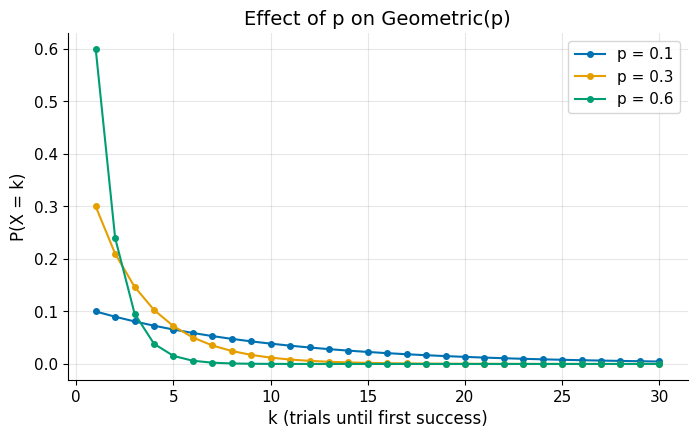

In [3]:
k_values = np.arange(1, 31)
fig, ax = plt.subplots()
for p_value, color in zip([0.1, 0.3, 0.6], COLORS):
    ax.plot(k_values, stats.geom(p_value).pmf(k_values), "o-", markersize=4, color=color, label=f"p = {p_value}")
ax.set_title("Effect of p on Geometric(p)")
ax.set_xlabel("k (trials until first success)")
ax.set_ylabel("P(X = k)")
ax.legend()
plt.show()

### 7.3 Negative Binomial: effect of r
With p = 0.3 fixed, the number of trials until the r-th success. Note `scipy` counts failures, so we add r to get trials.

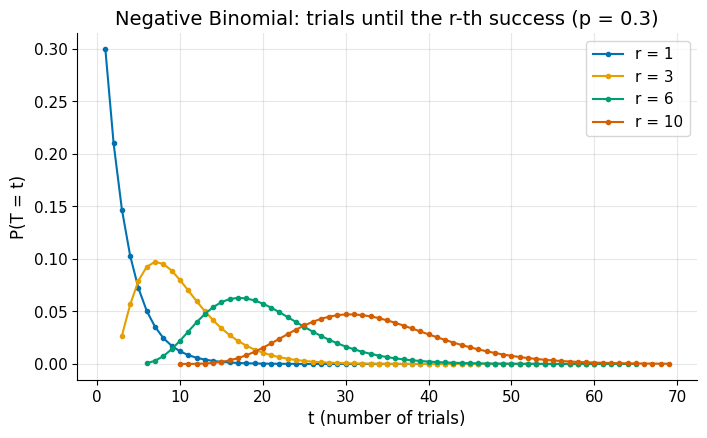

In [4]:
p = 0.3
fig, ax = plt.subplots()
for r_value, color in zip([1, 3, 6, 10], COLORS):
    failures = np.arange(0, 60)
    trials = failures + r_value                      # trials = failures + r
    ax.plot(trials, stats.nbinom(r_value, p).pmf(failures), "o-", markersize=3, color=color, label=f"r = {r_value}")
ax.set_title("Negative Binomial: trials until the r-th success (p = 0.3)")
ax.set_xlabel("t (number of trials)")
ax.set_ylabel("P(T = t)")
ax.legend()
plt.show()

### 7.4 Memorylessness check
The conditional distribution of the remaining wait, given we have already waited m trials, is the same as the original. We compare the original PMF with the PMF conditioned on X > 5, shifted by 5.

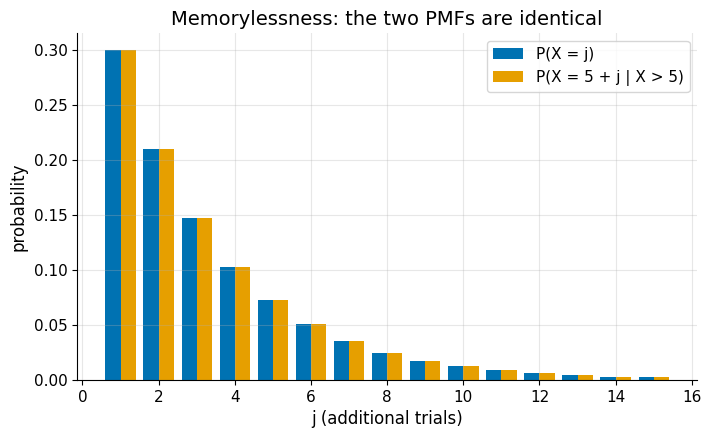

In [5]:
p = 0.3
dist = stats.geom(p)
m = 5
remaining = np.arange(1, 16)
original = dist.pmf(remaining)
conditional = dist.pmf(remaining + m) / dist.sf(m)     # P(X = m + j | X > m)

fig, ax = plt.subplots()
width = 0.4
ax.bar(remaining - width / 2, original, width=width, color=MAIN, label="P(X = j)")
ax.bar(remaining + width / 2, conditional, width=width, color=SIM, label="P(X = 5 + j | X > 5)")
ax.set_title("Memorylessness: the two PMFs are identical")
ax.set_xlabel("j (additional trials)")
ax.set_ylabel("probability")
ax.legend()
plt.show()
assert np.allclose(original, conditional)

## 8. 3D visuals

### 8.1 Geometric PMF over (k, p)
For every p a decaying row. Larger p concentrates the mass at k = 1.

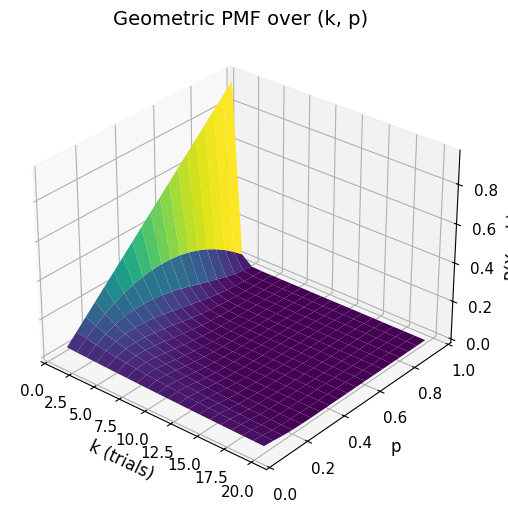

In [6]:
k_values = np.arange(1, 21)
p_values = np.linspace(0.05, 0.95, 19)
K, P = np.meshgrid(k_values, p_values)
Z = stats.geom.pmf(K, P)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(K, P, Z, cmap="viridis", edgecolor="none")
ax.set_title("Geometric PMF over (k, p)")
ax.set_xlabel("k (trials)")
ax.set_ylabel("p")
ax.set_zlabel("P(X = k)")
ax.view_init(elev=30, azim=-50)
plt.show()

### 8.2 Negative Binomial PMF over (t, r), p = 0.3
The ridge moves right and flattens as r grows (mean r/p).

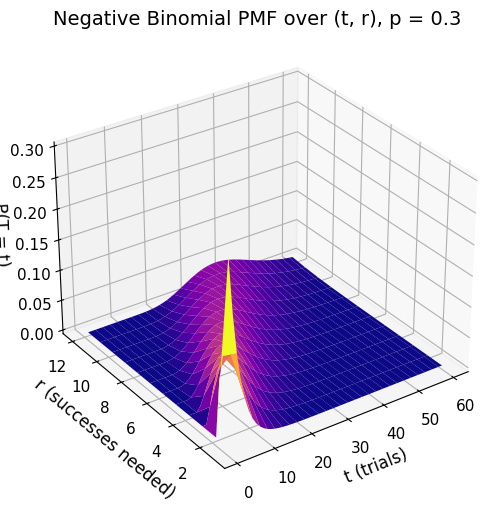

In [7]:
p = 0.3
r_values = np.arange(1, 13)
t_values = np.arange(1, 61)
T, R = np.meshgrid(t_values, r_values)
Z = np.where(T >= R, stats.nbinom.pmf(T - R, R, p), 0.0)   # zero where fewer trials than successes

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(T, R, Z, cmap="plasma", edgecolor="none")
ax.set_title("Negative Binomial PMF over (t, r), p = 0.3")
ax.set_xlabel("t (trials)")
ax.set_ylabel("r (successes needed)")
ax.set_zlabel("P(T = t)")
ax.view_init(elev=30, azim=-125)
plt.show()

### 8.3 Interactive Plotly version (Negative Binomial)
Same surface as 8.2, rotate and hover.

In [8]:
fig = go.Figure(go.Surface(x=t_values, y=r_values, z=Z, colorscale="Plasma"))
fig.update_layout(title="Negative Binomial PMF over (t, r), p = 0.3", width=750, height=550,
                  scene=dict(xaxis_title="t (trials)", yaxis_title="r", zaxis_title="P(T = t)"))
fig.show()

## 9. Simulation vs theory

### 9.1 Histograms against the PMFs
We simulate 20,000 waiting times for each distribution. `rng.geometric` uses the trials convention; `rng.negative_binomial` counts failures.

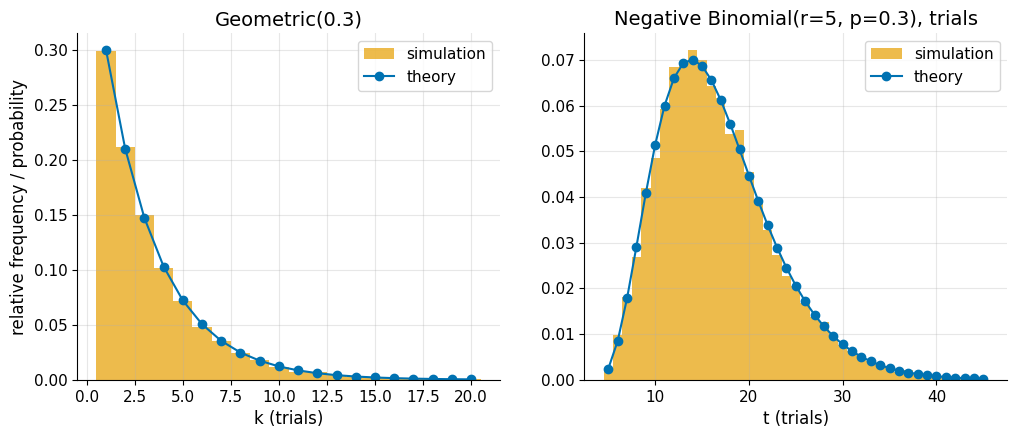

In [9]:
p = 0.3
r = 5
geom_samples = rng.geometric(p, size=20_000)
nbinom_trials = rng.negative_binomial(r, p, size=20_000) + r

fig, (ax_g, ax_n) = plt.subplots(1, 2, figsize=(12, 4.5))
k_values = np.arange(1, 21)
ax_g.hist(geom_samples, bins=np.arange(1, 22) - 0.5, density=True, color=SIM, alpha=0.7, label="simulation")
ax_g.plot(k_values, stats.geom(p).pmf(k_values), "o-", color=MAIN, label="theory")
ax_g.set_title("Geometric(0.3)")
ax_g.set_xlabel("k (trials)")
ax_g.set_ylabel("relative frequency / probability")
ax_g.legend()

t_values = np.arange(5, 46)
ax_n.hist(nbinom_trials, bins=np.arange(5, 47) - 0.5, density=True, color=SIM, alpha=0.7, label="simulation")
ax_n.plot(t_values, stats.nbinom(r, p).pmf(t_values - r), "o-", color=MAIN, label="theory")
ax_n.set_title("Negative Binomial(r=5, p=0.3), trials")
ax_n.set_xlabel("t (trials)")
ax_n.legend()
plt.show()

### 9.2 Running mean converges to 1/p
The average of the first m Geometric samples approaches 1/0.3 = 3.33.

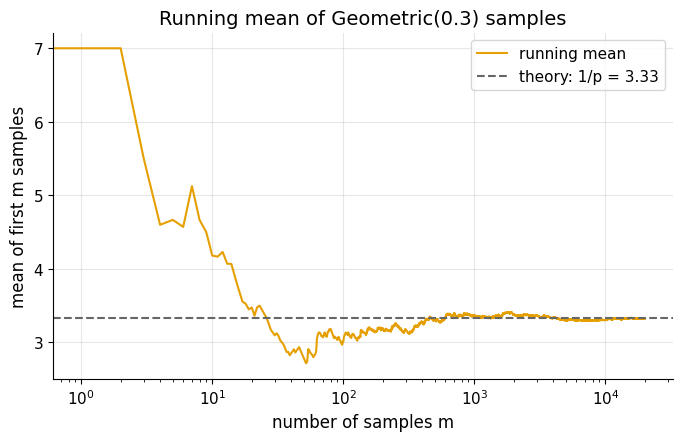

In [10]:
running_mean = np.cumsum(geom_samples) / np.arange(1, len(geom_samples) + 1)

fig, ax = plt.subplots()
ax.plot(running_mean, color=SIM, label="running mean")
ax.axhline(1 / p, color=NEUTRAL, linestyle="--", label="theory: 1/p = 3.33")
ax.set_title("Running mean of Geometric(0.3) samples")
ax.set_xlabel("number of samples m")
ax.set_ylabel("mean of first m samples")
ax.set_xscale("log")
ax.legend()
plt.show()

## 10. `scipy.stats` cheat sheet

Remember: `geom` counts trials (support starts at 1); `nbinom` counts failures (support starts at 0).

In [11]:
g = stats.geom(p=0.3)
print("geom pmf(3)     P(X = 3)   :", round(g.pmf(3), 5))
print("geom cdf(3)     P(X <= 3)  :", round(g.cdf(3), 5))
print("geom sf(3)      P(X > 3)   :", round(g.sf(3), 5), " (= 0.7**3 =", round(0.7**3, 5), ")")
print("geom ppf(0.9)   :", g.ppf(0.9))
print("geom mean, var  :", g.mean(), g.var())
print("geom interval   :", g.interval(0.9))

nbd = stats.nbinom(n=5, p=0.3)          # n here means r, the number of successes needed
print("nbinom pmf(10)  P(10 failures before the 5th success):", round(nbd.pmf(10), 5))
print("nbinom mean, var (failures):", nbd.mean(), nbd.var())
print("nbinom rvs      :", nbd.rvs(size=5, random_state=1))

geom pmf(3)     P(X = 3)   : 0.147
geom cdf(3)     P(X <= 3)  : 0.657
geom sf(3)      P(X > 3)   : 0.343  (= 0.7**3 = 0.343 )
geom ppf(0.9)   : 7.0
geom mean, var  : 3.3333333333333335 7.777777777777779
geom interval   : (np.float64(1.0), np.float64(9.0))
nbinom pmf(10)  P(10 failures before the 5th success): 0.06871
nbinom mean, var (failures): 11.666666666666668 38.88888888888889
nbinom rvs      : [18  8  8 15  9]


**Fitting:** there is no built-in `fit` for these. For the Geometric, the MLE is $\hat p=1/\bar x$. For the Negative Binomial we use the method of moments (shown in section 11.6).

In [12]:
observed_waits = rng.geometric(0.15, size=500)
p_hat = 1 / observed_waits.mean()
print(f"true p = 0.15, estimated p = {p_hat:.4f}")

true p = 0.15, estimated p = 0.1539


## 11. Real-world worked example: a sales rep making calls

**Scenario (illustrative numbers).** A sales rep closes a sale on **15 %** of calls, independently. Let $X$ be the number of calls until the first sale, so $X\sim\text{Geom}(0.15)$. To hit a daily target, the rep needs **5 sales**, so the number of calls $T\sim\text{NB}(r=5,p=0.15)$.

**Questions**
1. Expected number of calls until the first sale?
2. Probability the first sale comes within 5 calls?
3. For 5 sales: mean, SD and 90th percentile of the number of calls (to set a daily call target).

### 11.1 By hand
**Q1.** $E[X]=\dfrac1p=\dfrac1{0.15}=6.667$ calls.

**Q2.** $P(X\le5)=1-(1-p)^5=1-0.85^5$. Compute: $0.85^2=0.7225$, $0.85^4=0.7225^2=0.52200625$, $0.85^5=0.52200625\times0.85=0.4437053$. So $P(X\le5)=1-0.4437053=0.5562947$.

**Q3.** Mean $=\dfrac rp=\dfrac5{0.15}=33.33$. Variance $=\dfrac{r(1-p)}{p^2}=\dfrac{5\times0.85}{0.0225}=\dfrac{4.25}{0.0225}=188.89$, so SD $=\sqrt{188.89}=13.74$. The 90th percentile needs the PMF $\binom{t-1}{4}0.15^5\,0.85^{t-5}$ summed until it reaches 0.9, done by explicit loop below. A normal guess: $33.33+1.2816\times13.74\approx50.9$ (the real distribution is right-skewed, so expect a bit more (code gives 52)).

In [13]:
import math

p_close = 0.15
r_sales = 5

mean_first_hand = 1 / p_close
p_within_5_hand = 1 - 0.85**5
mean_calls_hand = r_sales / p_close
sd_calls_hand = math.sqrt(r_sales * (1 - p_close)) / p_close

def nb_trials_pmf(t):
    # C(t-1, r-1) p^r (1-p)^(t-r): the formula from section 4
    return math.comb(t - 1, r_sales - 1) * p_close**r_sales * (1 - p_close)**(t - r_sales)

running_total = 0.0
t = r_sales
while running_total < 0.90:           # add PMF terms until the total reaches 0.90
    running_total += nb_trials_pmf(t)
    t += 1
p90_calls_hand = t - 1
print(mean_first_hand, round(p_within_5_hand, 6), round(mean_calls_hand, 2), round(sd_calls_hand, 2), p90_calls_hand)

6.666666666666667 0.556295 33.33 13.74 52


### 11.2 In code with `scipy`, and the asserts
The Geometric uses trials directly. For the Negative Binomial we convert: trials = failures + r.

In [14]:
first_sale = stats.geom(p=p_close)
five_sales = stats.nbinom(n=r_sales, p=p_close)       # counts failures; add r for the number of calls

mean_first_code = first_sale.mean()
p_within_5_code = first_sale.cdf(5)
mean_calls_code = five_sales.mean() + r_sales
sd_calls_code = five_sales.std()                      # shifting by r does not change the SD
p90_calls_code = five_sales.ppf(0.90) + r_sales

assert np.isclose(mean_first_hand, mean_first_code)
assert np.isclose(p_within_5_hand, p_within_5_code)
assert np.isclose(mean_calls_hand, mean_calls_code)
assert np.isclose(sd_calls_hand, sd_calls_code)
assert np.isclose(p90_calls_hand, p90_calls_code)
print(f"E[calls to first sale] = {mean_first_code:.3f}")
print(f"P(first sale within 5 calls) = {p_within_5_code:.4f}")
print(f"5 sales: mean {mean_calls_code:.2f}, sd {sd_calls_code:.2f}, 90th percentile {p90_calls_code:.0f} calls")

E[calls to first sale] = 6.667
P(first sale within 5 calls) = 0.5563
5 sales: mean 33.33, sd 13.74, 90th percentile 52 calls


### 11.3 Verify by simulation
Simulate 50,000 days of calling until 5 sales, and 50,000 first-sale waits.

In [15]:
first_waits = rng.geometric(p_close, size=50_000)
calls_for_5 = rng.negative_binomial(r_sales, p_close, size=50_000) + r_sales

print(f"mean first sale:      exact {mean_first_code:.3f}  simulated {first_waits.mean():.3f}")
print(f"P(within 5 calls):    exact {p_within_5_code:.4f}  simulated {np.mean(first_waits <= 5):.4f}")
print(f"mean calls for 5:     exact {mean_calls_code:.2f}  simulated {calls_for_5.mean():.2f}")
print(f"90th pct calls for 5: exact {p90_calls_code:.0f}  simulated {np.percentile(calls_for_5, 90):.0f}")
assert abs(np.mean(first_waits <= 5) - p_within_5_code) < 0.01
assert abs(calls_for_5.mean() - mean_calls_code) < 0.5

mean first sale:      exact 6.667  simulated 6.628
P(within 5 calls):    exact 0.5563  simulated 0.5592
mean calls for 5:     exact 33.33  simulated 33.26
90th pct calls for 5: exact 52  simulated 51


### 11.4 Plots with the regions shaded
Left: P(first sale within 5 calls). Right: calls needed for 5 sales, with the mean and 90th percentile marked.

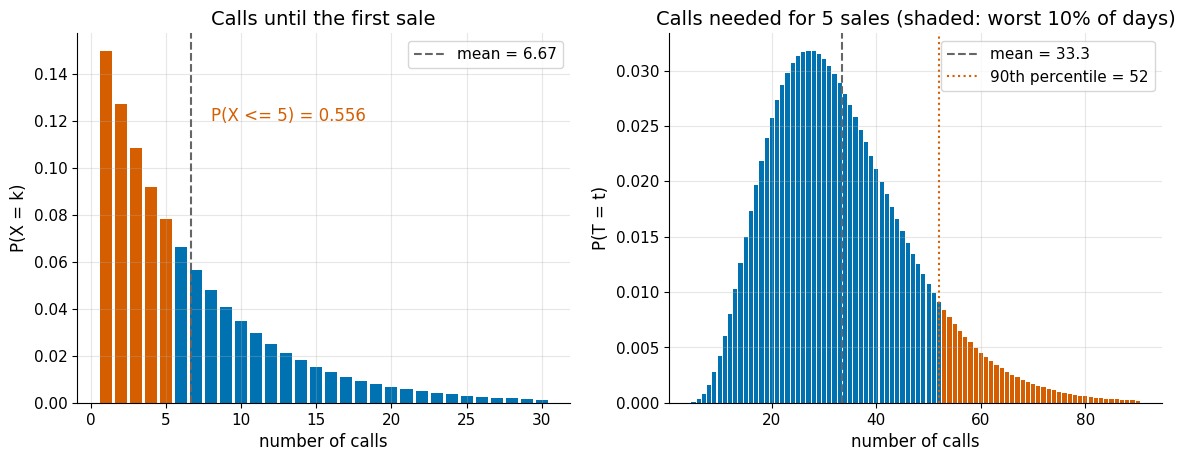

In [16]:
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(14, 4.8))

k_values = np.arange(1, 31)
ax_left.bar(k_values, first_sale.pmf(k_values), color=MAIN)
within = k_values <= 5
ax_left.bar(k_values[within], first_sale.pmf(k_values[within]), color=HIGHLIGHT)
ax_left.axvline(mean_first_code, color=NEUTRAL, linestyle="--", label="mean = 6.67")
ax_left.text(8, 0.12, f"P(X <= 5) = {p_within_5_code:.3f}", color=HIGHLIGHT, fontsize=12)
ax_left.set_title("Calls until the first sale")
ax_left.set_xlabel("number of calls")
ax_left.set_ylabel("P(X = k)")
ax_left.legend()

t_values = np.arange(5, 91)
pmf_t = five_sales.pmf(t_values - r_sales)
ax_right.bar(t_values, pmf_t, color=MAIN)
beyond = t_values > p90_calls_code
ax_right.bar(t_values[beyond], pmf_t[beyond], color=HIGHLIGHT)
ax_right.axvline(mean_calls_code, color=NEUTRAL, linestyle="--", label="mean = 33.3")
ax_right.axvline(p90_calls_code, color=HIGHLIGHT, linestyle=":", label=f"90th percentile = {p90_calls_code:.0f}")
ax_right.set_title("Calls needed for 5 sales (shaded: worst 10% of days)")
ax_right.set_xlabel("number of calls")
ax_right.set_ylabel("P(T = t)")
ax_right.legend()
plt.show()

### 11.5 Interpretation and decision
- On average the rep needs about **6.7 calls per sale**, but luck matters: there is a **56 %** chance of a sale within 5 calls, and a **44 %** chance of 5 straight misses.
- To reach 5 sales the rep needs about **33 calls on average**, with a large spread (SD about 14).
- **Decision:** set the daily target at the **90th percentile, about 52 calls**, so that the 5-sale goal is reachable on 9 days out of 10. A target of 33 calls would be missed on about half of the days.

### 11.6 Second example: insurance claim counts (variance greater than mean)
A small insurer records the number of claims per policy in a year. **The data below are synthetic**, generated to mimic real overdispersion: mean about 1.0 but variance about 1.6. We fit a Poisson and a Negative Binomial and compare.

In [17]:
claims = rng.negative_binomial(n=1.5, p=1.5 / (1.5 + 1.0), size=3000)   # true mean 1.0, variance about 1.67
sample_mean = claims.mean()
sample_var = claims.var()
print(f"sample mean = {sample_mean:.3f}, sample variance = {sample_var:.3f}")
print("Poisson would need variance = mean; the ratio here is", round(sample_var / sample_mean, 2))

sample mean = 1.002, sample variance = 1.593
Poisson would need variance = mean; the ratio here is 1.59


The variance is clearly larger than the mean, so Poisson is suspect. Method of moments for the Negative Binomial: with mean $\mu$ and variance $v>\mu$, $r=\mu^2/(v-\mu)$ and $p=\mu/v$.

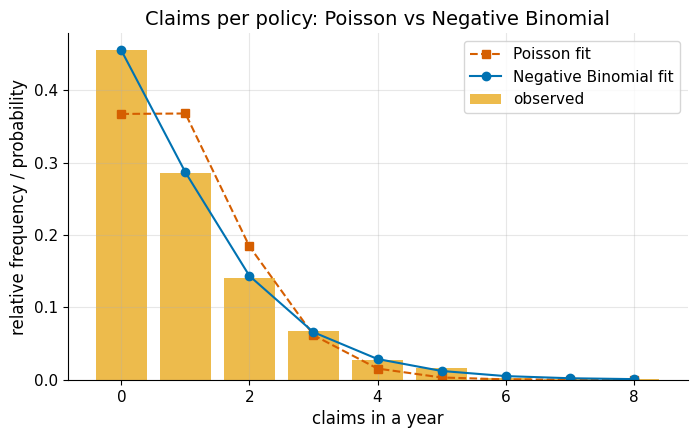

log-likelihood: Poisson -4300.6, Negative Binomial -4136.6


In [18]:
r_hat = sample_mean**2 / (sample_var - sample_mean)
p_hat = sample_mean / sample_var
poisson_fit = stats.poisson(mu=sample_mean)
nbinom_fit = stats.nbinom(n=r_hat, p=p_hat)

ks = np.arange(0, 9)
observed = np.bincount(claims, minlength=9)[:9] / len(claims)

fig, ax = plt.subplots()
ax.bar(ks, observed, color=SIM, alpha=0.7, label="observed")
ax.plot(ks, poisson_fit.pmf(ks), "s--", color=HIGHLIGHT, label="Poisson fit")
ax.plot(ks, nbinom_fit.pmf(ks), "o-", color=MAIN, label="Negative Binomial fit")
ax.set_title("Claims per policy: Poisson vs Negative Binomial")
ax.set_xlabel("claims in a year")
ax.set_ylabel("relative frequency / probability")
ax.legend()
plt.show()

loglik_poisson = poisson_fit.logpmf(claims).sum()
loglik_nbinom = nbinom_fit.logpmf(claims).sum()
print(f"log-likelihood: Poisson {loglik_poisson:.1f}, Negative Binomial {loglik_nbinom:.1f}")
assert loglik_nbinom > loglik_poisson

The Negative Binomial matches the heavy right tail and the excess zeros; Poisson underestimates both. It has a higher log-likelihood with only one extra parameter, so it is the better model. Practical consequence: Poisson would badly underestimate the chance of a policy with 4 or more claims.

In [19]:
print(f"P(4+ claims): observed {np.mean(claims >= 4):.4f}, Poisson {poisson_fit.sf(3):.4f}, NegBin {nbinom_fit.sf(3):.4f}")

P(4+ claims): observed 0.0493, Poisson 0.0191, NegBin 0.0491


---
### Example 2: retrying a failing API call (the Geometric distribution)

**Scenario (illustrative numbers).** An API call succeeds with probability **0.8** on each attempt, independently. Let $X$ be the number of attempts until the first success. The client gives up after **3 attempts**.

**Questions**
1. What are $P(X=1)$, $P(X\le3)$ and the expected number of attempts?
2. How many attempts must be allowed so that the call finally succeeds with probability at least **99.9 %**?
3. Three attempts have already failed. What is the probability that the next two also fail? Compare with $P(X>2)$.

### 11.6 By hand

**Q1.** $P(X=1)=0.8$; $P(X\le3)=1-0.2^3=\mathbf{0.992}$; $E[X]=1/0.8=\mathbf{1.25}$ attempts.

**Q2.** Need $1-0.2^n\ge0.999\iff0.2^n\le0.001\iff n\ge\ln0.001/\ln0.2=4.29$, so **5 attempts**.

**Q3.** By memorylessness $P(X>5\mid X>3)=P(X>2)=0.2^2=\mathbf{0.04}$: the earlier failures do not change the chance of failing twice more.

P(X = 1) = 0.80 | P(X <= 3) = 0.9920 | E[X] = 1.25, SD = 0.559 | attempts for 99.9 %: 5 | P(X > 5 | X > 3) = 0.0400 = P(X > 2) = 0.0400
simulation: mean attempts 1.251, P(X <= 3) = 0.9918, P(X > 5 | X > 3) = 0.0395


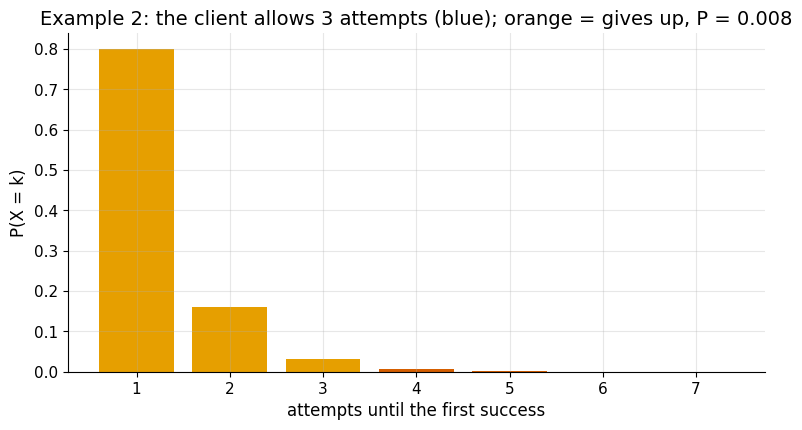

In [20]:
p_a = 0.8; geo_a = stats.geom(p_a)
n_need_a = int(np.ceil(np.log(0.001) / np.log(1 - p_a)))
cond_a = geo_a.sf(5) / geo_a.sf(3)
print(f"P(X = 1) = {geo_a.pmf(1):.2f} | P(X <= 3) = {geo_a.cdf(3):.4f} | E[X] = {geo_a.mean():.2f}, SD = {geo_a.std():.3f} | attempts for 99.9 %: {n_need_a} | P(X > 5 | X > 3) = {cond_a:.4f} = P(X > 2) = {geo_a.sf(2):.4f}")
assert np.isclose(geo_a.cdf(3), 0.992) and n_need_a == 5 and np.isclose(cond_a, geo_a.sf(2)) and np.isclose(geo_a.mean(), 1.25)
att_a = np.random.default_rng(6).geometric(p_a, 500_000)
print(f"simulation: mean attempts {att_a.mean():.3f}, P(X <= 3) = {np.mean(att_a <= 3):.4f}, P(X > 5 | X > 3) = {np.mean(att_a[att_a > 3] > 5):.4f}")
assert abs(np.mean(att_a <= 3) - 0.992) < 0.001 and abs(np.mean(att_a[att_a > 3] > 5) - 0.04) < 0.004
ks_a = np.arange(1, 8); fig, ax = plt.subplots(figsize=(9, 4.4))
ax.bar(ks_a, geo_a.pmf(ks_a), color=[SIM] * 3 + [HIGHLIGHT] * 4); ax.set_xlabel("attempts until the first success"); ax.set_ylabel("P(X = k)"); ax.set_title("Example 2: the client allows 3 attempts (blue); orange = gives up, P = 0.008")
plt.show()

### 11.7 Interpretation and decision (Example 2)

- **Most calls succeed at once** (80 %), and with three attempts the call eventually succeeds **99.2 %** of the time; the expected number of attempts is only **1.25**, so retries add little load on average.
- To reach **99.9 %** you need five attempts, because each extra attempt multiplies the failure probability by 0.2.
- Memorylessness matters for design: after three failures the next attempt is no more or less likely to work, which suggests that the failures come from the *server's chance* each time; if failures were clustered (an outage) the independence assumption would break and retrying immediately would not help.
- **Decision.** Allow 3 retries with a short backoff for transient errors; if the call still fails, escalate instead of retrying forever.

---
### Example 3: interviews until enough agree (the Negative Binomial distribution)

**Scenario (illustrative).** A researcher needs **4 interviewees who agree** to a follow-up study. Each person contacted agrees with probability **0.3**, independently. Let $T$ be the number of people contacted until the 4th agreement, $T\sim\text{NB}(r=4,p=0.3)$.

**Questions**
1. What are the mean and standard deviation of $T$?
2. What is the probability that **10 contacts** are enough?
3. How many contacts should be planned to be **90 % sure** of getting 4 agreements?

### 11.8 By hand

**Q1.** $E[T]=r/p=4/0.3=\mathbf{13.33}$ contacts; $\mathrm{Var}(T)=r(1-p)/p^2=4(0.7)/0.09=31.1$, so $\mathrm{SD}=\mathbf{5.58}$.

**Q2.** "4th success within 10 trials" means at least 4 successes among 10 contacts: $P(T\le10)=P(\text{Bin}(10,0.3)\ge4)=\mathbf{0.350}$.

**Q3.** Find the smallest $m$ with $P(\text{Bin}(m,0.3)\ge4)\ge0.9$; computed below it is **$m=21$**.

mean 13.33, SD 5.58 (scipy: 13.33, 5.58) | P(T <= 10) = 0.3504 (nbinom cdf(6) = 0.3504) | contacts for 90 %: 21
simulation: mean 13.323, SD 5.567, P(T <= 10) = 0.3508, 90th percentile = 21


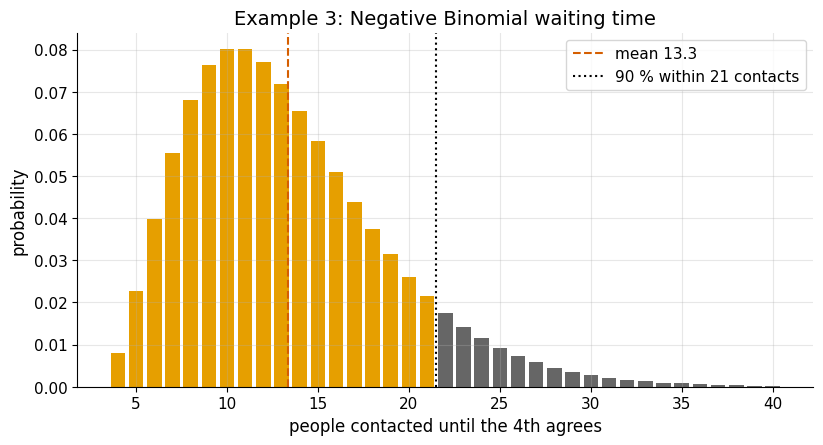

In [21]:
r_b, p_b = 4, 0.3
tb = stats.nbinom(r_b, p_b)                                   # counts failures before the 4th success, so contacts = failures + 4
mean_t, sd_t = r_b / p_b, np.sqrt(r_b * (1 - p_b)) / p_b
p10 = stats.binom(10, p_b).sf(3)
m90 = next(mm_b for mm_b in range(4, 100) if stats.binom(mm_b, p_b).sf(3) >= 0.9)
print(f"mean {mean_t:.2f}, SD {sd_t:.2f} (scipy: {tb.mean() + r_b:.2f}, {tb.std():.2f}) | P(T <= 10) = {p10:.4f} (nbinom cdf(6) = {tb.cdf(6):.4f}) | contacts for 90 %: {m90}")
assert np.isclose(tb.mean() + r_b, mean_t) and np.isclose(tb.std(), sd_t) and np.isclose(p10, tb.cdf(10 - r_b)) and m90 == 21
sim_b = np.random.default_rng(9).negative_binomial(r_b, p_b, 500_000) + r_b
print(f"simulation: mean {sim_b.mean():.3f}, SD {sim_b.std():.3f}, P(T <= 10) = {np.mean(sim_b <= 10):.4f}, 90th percentile = {np.percentile(sim_b, 90):.0f}")
assert abs(sim_b.mean() - mean_t) < 0.05 and abs(np.mean(sim_b <= 10) - p10) < 0.003
ts_b = np.arange(4, 41); fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.bar(ts_b, tb.pmf(ts_b - r_b), color=[SIM if tt_b <= m90 else NEUTRAL for tt_b in ts_b]); ax.axvline(mean_t, color=HIGHLIGHT, linestyle="--", label=f"mean {mean_t:.1f}"); ax.axvline(m90 + 0.5, color="black", linestyle=":", label="90 % within 21 contacts")
ax.set_xlabel("people contacted until the 4th agrees"); ax.set_ylabel("probability"); ax.set_title("Example 3: Negative Binomial waiting time"); ax.legend()
plt.show()

### 11.9 Interpretation and decision (Example 3)

- On average **13.3 contacts** are needed, but the spread is large (SD 5.6): there is only a **35 % chance** that 10 contacts are enough, and a 4th agreement takes 25 or more contacts in about 4 % of studies.
- Planning for the *mean* would leave the study short 45 % of the time; to be **90 % sure** the researcher should plan for **21 contacts** (the simulation's 90th percentile is also 21).
- **Decision.** Budget for the 90th percentile (21 contacts, about 60 % more than the mean) and keep a reserve list. The extra cost is the price of reducing the risk of delay from about one in two to one in ten.

## 12. Where it is used

### Statistics
- **Overdispersed counts:** when variance exceeds mean, Negative Binomial replaces Poisson in count models.
- **Sequential trials:** the Geometric gives the distribution of the stopping time of "repeat until success" experiments.

### Data science
- **Churn and retention:** with a constant per-period churn probability, months until a customer leaves is Geometric (mean 1/p).
- **Retries and backoff:** the number of attempts until an API call succeeds.
- **Overdispersed event counts** such as claims per policy, support tickets per user, or purchases per customer.

### ML and AI
- **Negative Binomial regression** (a GLM) for counts with extra variance, and NB likelihoods in RNA-seq models and some recommender and demand models.
- **Geometric stopping times** appear in reinforcement learning (episode lengths with a constant termination probability, discount factor $\gamma$ as a continuation probability).

## 13. Common pitfalls and misconceptions

- **Convention mix-ups:** `scipy.stats.geom` counts trials (starts at 1); `numpy` `rng.geometric` also starts at 1; but `scipy.stats.nbinom` and `rng.negative_binomial` count failures. Always say which one you use.
- **The gambler's fallacy:** after many failures, success is not "due". Memorylessness says the chance is still p.
- **Mean waiting time is not a guarantee:** the Geometric is very skewed; the median is below the mean, and long waits are common.
- **Using Poisson when variance is much larger than the mean** gives overconfident tails. Check the variance-to-mean ratio.
- **Two parameterizations of the Negative Binomial:** (r, p) and (mean, dispersion). Check which one a library expects.

## 14. Exercises

1. A die is rolled until a 6 appears. What is the expected number of rolls and the probability that it takes more than 10?
2. A free-throw shooter makes 70 % of shots. What is the probability the first miss occurs on the 4th shot?
3. Prove that if $X\sim\text{Geom}(p)$ then $P(X>m+n\mid X>m)=P(X>n)$ without looking at the notes.
4. A website retries a failed upload with success probability 0.8 each try. How many tries are needed so that the upload has succeeded with probability at least 99.9 %?
5. A machine produces a defective part with probability 0.02. What is the mean and SD of the number of parts made until the 3rd defect?
6. Using the code, plot the CDF of the number of calls for 5 sales (section 11) and read off the median. Is it below or above the mean 33.3?
7. (Harder) Show with PGFs that the sum of two independent Geom($p$) variables is NB($2,p$).
8. (Harder) A count variable has mean 4 and variance 10. Find the Negative Binomial $(r,p)$ by moments, and compare $P(X=0)$ with the Poisson value.

9. A fair die is rolled until the first 6 appears. Find $E[X]$, $\mathrm{Var}(X)$ and $P(X>12)$.
10. How many rolls are needed on average to see the **third** six? Find the standard deviation and $P(T\le12)$, and check with the Binomial.
11. Let $p=0.2$. Verify numerically that $P(X>10\mid X>4)=P(X>6)$ and explain in one sentence why a gambler who has lost 4 times in a row is not \"due\" for a win.

Solutions are at the end.

## 15. Summary table

| Item | Geometric | Negative Binomial |
|---|---|---|
| Parameters | p | r (successes needed), p |
| Support (trials) | 1, 2, 3, ... | r, r+1, ... |
| PMF | (1-p)^(k-1) p | C(t-1, r-1) p^r (1-p)^(t-r) |
| Mean | 1/p | r/p |
| Variance | (1-p)/p^2 | r(1-p)/p^2 |
| When to use | trials until the first success; memoryless waiting | trials until the r-th success; overdispersed counts |
| `scipy` name | `stats.geom(p)` (trials) | `stats.nbinom(n=r, p)` (failures) |

## Solutions

In [22]:
print("1:", 1 / (1 / 6), " P(>10) =", (5 / 6)**10, stats.geom(1 / 6).sf(10))
print("2:", 0.7**3 * 0.3)
print("4: tries needed =", int(np.ceil(np.log(0.001) / np.log(0.2))), " check", 1 - 0.2**5)
print("5: mean =", 3 / 0.02, " sd =", np.sqrt(3 * 0.98) / 0.02)

five_sales_cdf = stats.nbinom(5, 0.15).cdf(np.arange(0, 120))
median_calls = np.argmax(five_sales_cdf >= 0.5) + 5
print("6: median calls =", median_calls, "(mean 33.3)")

mu, v = 4.0, 10.0
r8 = mu**2 / (v - mu)
p8 = mu / v
print(f"8: r = {r8:.3f}, p = {p8:.2f}, P(X=0): NegBin {stats.nbinom(r8, p8).pmf(0):.4f} vs Poisson {stats.poisson(mu).pmf(0):.4f}")

1: 6.0  P(>10) = 0.1615055828898458 0.1615055828898457
2: 0.10289999999999998
4: tries needed = 5  check 0.99968
5: mean = 150.0  sd = 85.73214099741124
6: median calls = 31 (mean 33.3)
8: r = 2.667, p = 0.40, P(X=0): NegBin 0.0869 vs Poisson 0.0183


**1.** Mean $1/p=6$ rolls; $P(X>10)=(5/6)^{10}\approx0.1615$.

**2.** The first miss on shot 4 means 3 makes then a miss: $0.7^3\times0.3\approx0.1029$.

**3.** $\dfrac{P(X>m+n)}{P(X>m)}=\dfrac{(1-p)^{m+n}}{(1-p)^m}=(1-p)^n=P(X>n)$.

**4.** Need $1-0.2^k\ge0.999$, so $k\ge\ln0.001/\ln0.2=4.29$, hence 5 tries.

**5.** Mean $r/p=150$ parts, SD $\sqrt{3\times0.98}/0.02\approx85.7$.

**6.** The median is below the mean because the distribution is right-skewed.

**7.** Each Geometric has PGF $\frac{ps}{1-qs}$; independent sums multiply PGFs, giving $\big(\frac{ps}{1-qs}\big)^2$, which is the NB($r=2$) PGF.

**8.** $r=\mu^2/(v-\mu)=16/6\approx2.67$, $p=\mu/v=0.4$. The Negative Binomial puts more mass at 0 than Poisson (see printed values), reflecting the extra variance.

### Solutions to the additional exercises

Each answer is computed below and checked.

In [23]:
g6 = stats.geom(1 / 6)
print(f"6: E[X] = {g6.mean():.1f}, Var = {g6.var():.1f}, P(X > 12) = {g6.sf(12):.4f} = (5/6)^12 = {(5 / 6) ** 12:.4f}")
nb7 = stats.nbinom(3, 1 / 6); mean7, sd7 = nb7.mean() + 3, nb7.std()
print(f"7: mean {mean7:.1f} rolls, SD {sd7:.2f} | P(T <= 12) = {nb7.cdf(9):.4f} = P(Bin(12, 1/6) >= 3) = {stats.binom(12, 1 / 6).sf(2):.4f}")
g8 = stats.geom(0.2); lhs8, rhs8 = g8.sf(10) / g8.sf(4), g8.sf(6)
print(f"8: P(X > 10 | X > 4) = {lhs8:.5f} = P(X > 6) = {rhs8:.5f}: the next trials are independent of the earlier ones")
assert np.isclose(g6.mean(), 6) and np.isclose(g6.var(), 30) and np.isclose(nb7.cdf(9), stats.binom(12, 1 / 6).sf(2)) and np.isclose(lhs8, rhs8)

6: E[X] = 6.0, Var = 30.0, P(X > 12) = 0.1122 = (5/6)^12 = 0.1122
7: mean 18.0 rolls, SD 9.49 | P(T <= 12) = 0.3226 = P(Bin(12, 1/6) >= 3) = 0.3226
8: P(X > 10 | X > 4) = 0.26214 = P(X > 6) = 0.26214: the next trials are independent of the earlier ones
